# Group Component 1

## Library versions, or environment settings

```
Python version: 3.12.2 | packaged by conda-forge | (main, Feb 16 2024, 20:54:21) [Clang 16.0.6 ]
Pandas version: 2.2.2
Scikit-learn version: 1.4.2
Numpy version: 1.26.4
Matplotlib version: 3.8.4
Imbalanced-learn version: 0.12.3
XGBoost version: 2.1.1
Seaborn version: 0.13.2
```

## imports

In [24]:
import pandas as pd
import sklearn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import cross_val_score, KFold
from sklearn import metrics
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, cohen_kappa_score, classification_report
from sklearn.preprocessing import StandardScaler

In [26]:
# insert own path to the csv
df = pd.read_csv('../data/raw/credit_records.csv')
# pandas view options
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)
pd.options.display.float_format = '{:}'.format
# numpy options
np.set_printoptions(suppress=True)

In [28]:
df.columns = df.columns.str.lower()
df.head()

,record_id,customer_id,record_month,customer_age,customer_occupation,annual_income,monthly_salary,bank_accounts,credit_cards,interest_rate,loans,loan_types,loan_types_2,loan_types_3,loan_types_4,loan_types_5,loan_types_6,loan_types_7,loan_types_8,loan_types_9,payment_delay_days,delayed_payments,credit_limit_changes,credit_inquiries,credit_mix,outstanding_debt,credit_utilization,credit_history_age,credit_history_age_months,min_amount_payment,monthly_emi,monthly_investment,payment_behavior,monthly_balance,credit_score
0,0x1602,CUS_0xd40,1,23,Scientist,19114.12,1824.84,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,and Home Equity Loan,NaN,NaN,NaN,NaN,NaN,3,7.0,11.27,4.0,Standard,809.98,26.82261962,22 Years and 1 Months,265.0,No,49.57494921,80.41529544,High_spent_Small_value_payments,312.4940887,Good
1,0x1603,CUS_0xd40,2,23,Scientist,19114.12,3096.38,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,and Home Equity Loan,NaN,NaN,NaN,NaN,NaN,1,14.0,11.27,4.0,Good,809.98,31.94496006,NaN,219.0,No,49.57494921,118.2802216,Low_spent_Large_value_payments,284.6291625,Good
2,0x1605,CUS_0xd40,4,23,Scientist,19114.12,3096.38,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,and Home Equity Loan,NaN,NaN,NaN,NaN,NaN,5,4.0,6.27,4.0,Good,809.98,31.37786187,22 Years and 4 Months,268.0,No,49.57494921,199.4580744,Low_spent_Small_value_payments,223.4513097,Good
3,0x1606,CUS_0xd40,5,23,Scientist,19114.12,1824.84,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,and Home Equity Loan,NaN,NaN,NaN,NaN,NaN,6,14.0,11.27,4.0,Good,809.98,24.79734691,22 Years and 5 Months,269.0,No,49.57494921,41.42015309,High_spent_Medium_value_payments,341.489231,Good
4,0x1607,CUS_0xd40,6,23,Scientist,19114.12,3096.38,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,and Home Equity Loan,NaN,NaN,NaN,NaN,NaN,8,4.0,9.27,4.0,Good,809.98,27.26225871,22 Years and 6 Months,270.0,No,49.57494921,62.43017233,NaN,340.4792118,Good


## cleaning

In [31]:
cols = ['loan_types', 'loan_types_2', 'loan_types_3', 'loan_types_4', 'loan_types_5', 'loan_types_6', 'loan_types_7', 'loan_types_8', 'loan_types_9']
df[cols] = df[cols].replace('and\\s+', '', regex=True)
df.head()

,record_id,customer_id,record_month,customer_age,customer_occupation,annual_income,monthly_salary,bank_accounts,credit_cards,interest_rate,loans,loan_types,loan_types_2,loan_types_3,loan_types_4,loan_types_5,loan_types_6,loan_types_7,loan_types_8,loan_types_9,payment_delay_days,delayed_payments,credit_limit_changes,credit_inquiries,credit_mix,outstanding_debt,credit_utilization,credit_history_age,credit_history_age_months,min_amount_payment,monthly_emi,monthly_investment,payment_behavior,monthly_balance,credit_score
0,0x1602,CUS_0xd40,1,23,Scientist,19114.12,1824.84,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,Home Equity Loan,NaN,NaN,NaN,NaN,NaN,3,7.0,11.27,4.0,Standard,809.98,26.82261962,22 Years and 1 Months,265.0,No,49.57494921,80.41529544,High_spent_Small_value_payments,312.4940887,Good
1,0x1603,CUS_0xd40,2,23,Scientist,19114.12,3096.38,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,Home Equity Loan,NaN,NaN,NaN,NaN,NaN,1,14.0,11.27,4.0,Good,809.98,31.94496006,NaN,219.0,No,49.57494921,118.2802216,Low_spent_Large_value_payments,284.6291625,Good
2,0x1605,CUS_0xd40,4,23,Scientist,19114.12,3096.38,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,Home Equity Loan,NaN,NaN,NaN,NaN,NaN,5,4.0,6.27,4.0,Good,809.98,31.37786187,22 Years and 4 Months,268.0,No,49.57494921,199.4580744,Low_spent_Small_value_payments,223.4513097,Good
3,0x1606,CUS_0xd40,5,23,Scientist,19114.12,1824.84,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,Home Equity Loan,NaN,NaN,NaN,NaN,NaN,6,14.0,11.27,4.0,Good,809.98,24.79734691,22 Years and 5 Months,269.0,No,49.57494921,41.42015309,High_spent_Medium_value_payments,341.489231,Good
4,0x1607,CUS_0xd40,6,23,Scientist,19114.12,3096.38,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,Home Equity Loan,NaN,NaN,NaN,NaN,NaN,8,4.0,9.27,4.0,Good,809.98,27.26225871,22 Years and 6 Months,270.0,No,49.57494921,62.43017233,NaN,340.4792118,Good


In [33]:
for index, row in df.iterrows():
  # check if credit_history_age and credit_history_age_months are both nan and 219
  if pd.isnull(row['credit_history_age']) and row['credit_history_age_months'] == 219:
    prev = df.loc[index - 1]
    after = df.loc[index + 1]
    # if the row above is the same customer, take the previous row + month diff
    if (row['customer_id'] == prev['customer_id']):
      df.at[index, 'credit_history_age_months'] = prev['record_month'] + (row['record_month'] - prev['record_month'])
    # if not the same customer, check the row after
    elif (row['customer_id'] == after['customer_id']):
      df.at[index, 'credit_history_age_months'] = after['record_month'] - (after['record_month'] - row['record_month'])
    else:
      df.at[index, 'credit_history_age_months'] = np.nan

  # check if ages are outliers. > 90
  if row['customer_age'] > 90:
    prev = df.loc[index - 1]
    after = df.loc[index + 1]
    if (row['customer_id'] == prev['customer_id']):
      df.at[index, 'customer_age'] = prev['customer_age']
    # if not the same customer, check the row after
    elif (row['customer_id'] == after['customer_id']):
      df.at[index, 'customer_age'] = after['customer_age']

In [34]:
iqr = df['annual_income'].quantile(0.75) + 1.5 * (df['annual_income'].quantile(0.75) - df['annual_income'].quantile(0.25))
df = df.drop(df[df['annual_income'] >= iqr].groupby('annual_income').filter(lambda x: len(x) <= 3).index)

In [35]:
df = df[~(df['credit_history_age_months'].isna()) & ~(df['payment_behavior'].isna())]

In [39]:
df['customer_occupation'] = df['customer_occupation'].fillna(
      df.groupby('customer_id')['customer_occupation'].transform(lambda x: pd.Series.mode(x)[0]))
df = df.drop(['credit_history_age', 'record_id', 'customer_id'], axis=1)

In [40]:
df['min_amount_payment'] = np.where(df['min_amount_payment'] == 'Yes', 1, 0).astype(int)

## split dataset into 80 train 20 test

In [150]:
df.reset_index(drop=True)

,record_month,customer_age,customer_occupation,annual_income,monthly_salary,bank_accounts,credit_cards,interest_rate,loans,loan_types,loan_types_2,loan_types_3,loan_types_4,loan_types_5,loan_types_6,loan_types_7,loan_types_8,loan_types_9,payment_delay_days,delayed_payments,credit_limit_changes,credit_inquiries,credit_mix,outstanding_debt,credit_utilization,credit_history_age_months,min_amount_payment,monthly_emi,monthly_investment,payment_behavior,monthly_balance,credit_score
0,1,23,Scientist,19114.12,1824.84,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,Home Equity Loan,NaN,NaN,NaN,NaN,NaN,3,7.0,11.27,4.0,Standard,809.98,26.82261962,265.0,0,49.57494921,80.41529544,High_spent_Small_value_payments,312.4940887,Good
1,2,23,Scientist,19114.12,3096.38,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,Home Equity Loan,NaN,NaN,NaN,NaN,NaN,1,14.0,11.27,4.0,Good,809.98,31.94496006,2.0,0,49.57494921,118.2802216,Low_spent_Large_value_payments,284.6291625,Good
2,4,23,Scientist,19114.12,3096.38,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,Home Equity Loan,NaN,NaN,NaN,NaN,NaN,5,4.0,6.27,4.0,Good,809.98,31.37786187,268.0,0,49.57494921,199.4580744,Low_spent_Small_value_payments,223.4513097,Good
3,5,23,Scientist,19114.12,1824.84,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,Home Equity Loan,NaN,NaN,NaN,NaN,NaN,6,14.0,11.27,4.0,Good,809.98,24.79734691,269.0,0,49.57494921,41.42015309,High_spent_Medium_value_payments,341.489231,Good
4,7,23,Scientist,19114.12,1824.84,3.0,4,3,4,Auto Loan,Credit-Builder Loan,Personal Loan,Home Equity Loan,NaN,NaN,NaN,NaN,NaN,3,8.0,11.27,4.0,Good,809.98,22.53759303,271.0,0,49.57494921,178.3440674,Low_spent_Small_value_payments,244.5653167,Good
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83519,3,25,Mechanic,39628.99,3359.42,4.0,6,7,2,Auto Loan,Student Loan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,20,6.0,9.5,3.0,Standard,502.38,39.32356936,377.0,0,35.10402261,140.5814027,High_spent_Medium_value_payments,410.256158,Poor
83520,4,25,Mechanic,39628.99,3359.42,4.0,6,7,2,Auto Loan,Student Loan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23,7.0,11.5,3.0,Standard,502.38,34.66357181,378.0,0,35.10402261,60.97133256,High_spent_Large_value_payments,479.8662282,Poor
83521,5,25,Mechanic,39628.99,3359.42,4.0,6,7,2,Auto Loan,Student Loan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18,7.0,11.5,3.0,Standard,502.38,40.56563096,379.0,0,35.10402261,54.18595029,High_spent_Medium_value_payments,496.6516104,Poor
83522,6,25,Mechanic,39628.99,3359.42,4.0,6,13,2,Auto Loan,Student Loan,NaN,NaN,NaN,NaN,NaN,NaN,NaN,27,6.0,11.5,3.0,Good,502.38,41.25552226,380.0,0,35.10402261,24.02847745,High_spent_Large_value_payments,516.8090833,Poor


In [152]:
y = df['credit_score']
X = df[df.columns.tolist()[:-1]]

# train+val test split in 80-20 ratio
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=108)
print(X_train.shape)
print(X_test.shape)

(66819, 31)
(16705, 31)


In [120]:
results = []

## End of Group Component 1

# Predictive Model: KNN Algorithm

In [122]:
y_train.replace({'Good': 2, 'Poor': 0, 'Standard': 1}, inplace=True)
y_test.replace({'Good': 2, 'Poor': 0, 'Standard': 1}, inplace=True)

In [124]:
from sklearn.pipeline import FunctionTransformer
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import f1_score, cohen_kappa_score, ConfusionMatrixDisplay

In [126]:
def encode_loans(X):
  tmp = pd.get_dummies(X.filter(like='loan_types').stack(dropna=False)).groupby(level=0).max().astype(int)
  return (X.join(tmp)).drop(cols, axis=1)

def encode_payment_behavior(X):
  tmp = pd.get_dummies(X['payment_behavior']).astype(int)
  return (X.join(tmp)).drop('payment_behavior', axis=1)

def encode_occupation(X):
  tmp = pd.get_dummies(X['customer_occupation']).astype(int)
  return (X.join(tmp)).drop('customer_occupation', axis=1)

In [128]:
ct = ColumnTransformer(
    [
        ('credit_mix', OrdinalEncoder(categories=[['Bad', 'Standard', 'Good']]), ['credit_mix']),
        ('standardizer', StandardScaler(), ['record_month', 'customer_age', 'annual_income', 'monthly_salary', 'bank_accounts',
                              'credit_cards', 'interest_rate', 'loans', 'payment_delay_days', 'delayed_payments',
                              'credit_limit_changes', 'credit_inquiries', 'outstanding_debt', 'credit_utilization',
                              'credit_history_age_months', 'min_amount_payment', 'monthly_emi', 'monthly_investment',
                              'monthly_balance']),
    ],
    remainder='passthrough',
    verbose_feature_names_out=False
)
ct.set_output(transform='pandas')

ColumnTransformer(remainder='passthrough',
                  transformers=[('credit_mix',
                                 OrdinalEncoder(categories=[['Bad', 'Standard',
                                                             'Good']]),
                                 ['credit_mix']),
                                ('standardizer', StandardScaler(),
                                 ['record_month', 'customer_age',
                                  'annual_income', 'monthly_salary',
                                  'bank_accounts', 'credit_cards',
                                  'interest_rate', 'loans',
                                  'payment_delay_days', 'delayed_payments',
                                  'credit_limit_changes', 'credit_inquiries',
                                  'outstanding_debt', 'credit_utilization',
                                  'credit_history_age_months',
                                  'min_amount_payment', 'monthly_emi',
                                  'monthly_investment', 'monthly_balance'])],
                  verbose_feature_names_out=False)

In [130]:
pipe = Pipeline([
    ('loan_encoder', FunctionTransformer(encode_loans)),
    ('payment_behavior_encoder', FunctionTransformer(encode_payment_behavior)),
    ('occupation_encoder', FunctionTransformer(encode_occupation)),
    ('ct', ct),
    ('oversampler', SMOTE()),
    ('pca', PCA(n_components=0.95, svd_solver='full')),
    ('clf', KNeighborsClassifier())
])

pipe.fit(X_train, y_train)

Pipeline(steps=[('loan_encoder',
                 FunctionTransformer(func=<function encode_loans at 0x346efaac0>)),
                ('payment_behavior_encoder',
                 FunctionTransformer(func=<function encode_payment_behavior at 0x346efa340>)),
                ('occupation_encoder',
                 FunctionTransformer(func=<function encode_occupation at 0x346efa2a0>)),
                ('ct',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[(...
                                                   'payment_delay_days',
                                                   'delayed_payments',
                                                   'credit_limit_changes',
                                                   'credit_inquiries',
                                                   'outstanding_debt',
                                                   'credit_utilization',
                                                   'credit_history_age_months',
                                                   'min_amount_payment',
                                                   'monthly_emi',
                                                   'monthly_investment',
                                                   'monthly_balance'])],
                                   verbose_feature_names_out=False)),
                ('oversampler', SMOTE()),
                ('pca', PCA(n_components=0.95, svd_solver='full')),
                ('clf', KNeighborsClassifier())])

F1 score:  0.6710377863995004
Cohen's kappa score:  0.49815124529768195


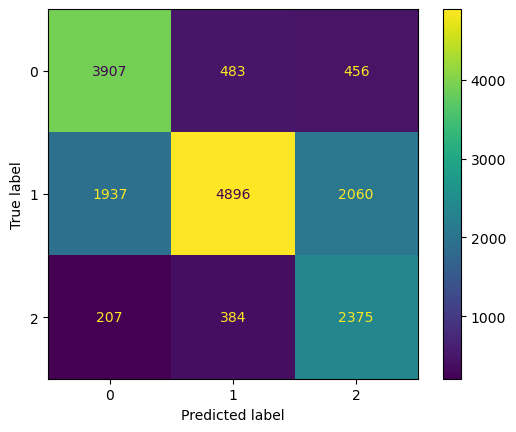

In [248]:
y_pred = pipe.predict(X_test)
print('F1 score: ', f1_score(y_test, y_pred, average='weighted'))
print("Cohen's kappa score: ", cohen_kappa_score(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(
   y_test, y_pred)

In [250]:
print('features kept after pca: ', pipe['pca'].n_components_)

features kept after pca:  30


In [252]:
print('total number of features: ', len(pipe[0:4].fit_transform(X_train, y_train).columns))

total number of features:  50


## optimization

In [255]:
from sklearn.model_selection import GridSearchCV

In [257]:
param_grid = {
    'pca': ['passthrough', PCA(n_components=0.95, svd_solver='full'), PCA(n_components=0.90, svd_solver='full'),
           PCA(n_components=0.80, svd_solver='full'), PCA(n_components=0.70, svd_solver='full'),
           PCA(n_components=0.60, svd_solver='full')],
    'oversampler': ['passthrough', SMOTE()],
    'clf__n_neighbors': [2, 5, 10, 15, 20, 25, 30],
    'clf__weights': ['uniform', 'distance'],
    'clf__metric' : ['l1', 'l2', 'cosine']
}

search = GridSearchCV(pipe, param_grid, n_jobs=-1, scoring='f1_weighted', verbose=10)
search.fit(X_train, y_train)

Fitting 5 folds for each of 504 candidates, totalling 2520 fits


[CV

 4/5; 56/504] START clf__metric=l1, clf__n_neighbors=10, clf__weights=uniform, oversampler=SMOTE(), pca=PCA(n_components=0.95, svd_solver='full')


GridSearchCV(estimator=Pipeline(steps=[('loan_encoder',
                                        FunctionTransformer(func=<function encode_loans at 0x339532200>)),
                                       ('payment_behavior_encoder',
                                        FunctionTransformer(func=<function encode_payment_behavior at 0x339531f80>)),
                                       ('occupation_encoder',
                                        FunctionTransformer(func=<function encode_occupation at 0x339530ae0>)),
                                       ('ct',
                                        ColumnTransformer(remainder='passt...
                         'clf__n_neighbors': [2, 5, 10, 15, 20, 25, 30],
                         'clf__weights': ['uniform', 'distance'],
                         'oversampler': ['passthrough', SMOTE()],
                         'pca': ['passthrough',
                                 PCA(n_components=0.95, svd_solver='full'),
                                 PCA(n_components=0.9, svd_solver='full'),
                                 PCA(n_components=0.8, svd_solver='full'),
                                 PCA(n_components=0.7, svd_solver='full'),
                                 PCA(n_components=0.6, svd_solver='full')]},
             scoring='f1_weighted', verbose=10)

In [263]:
y_pred = search.predict(X_test)
search.best_params_

{'clf__metric': 'l1',
 'clf__n_neighbors': 5,
 'clf__weights': 'distance',
 'oversampler': 'passthrough',
 'pca': 'passthrough'}

F1 score:  0.7955400047228899
Cohen's kappa score:  0.6606470388840562


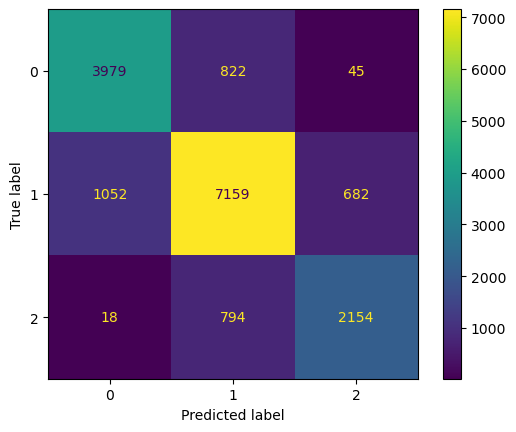

In [265]:
print('F1 score: ', f1_score(y_test, y_pred, average='weighted'))
print("Cohen's kappa score: ", cohen_kappa_score(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(
   y_test, y_pred)

In [267]:
param_grid = {
    'pca': ['passthrough'],
    'oversampler': ['passthrough'],
    'clf__n_neighbors': [5],
    'clf__weights': ['distance'],
    'clf__algorithm': ['ball_tree', 'kd_tree'],
    'clf__metric' : ['l1']
}

search = GridSearchCV(pipe, param_grid, n_jobs=-1, scoring='f1_weighted', verbose=10)
search.fit(X_train, y_train)

Fitting 5 folds for each of 2 candidates, totalling 10 fits


GridSearchCV(estimator=Pipeline(steps=[('loan_encoder',
                                        FunctionTransformer(func=<function encode_loans at 0x339532200>)),
                                       ('payment_behavior_encoder',
                                        FunctionTransformer(func=<function encode_payment_behavior at 0x339531f80>)),
                                       ('occupation_encoder',
                                        FunctionTransformer(func=<function encode_occupation at 0x339530ae0>)),
                                       ('ct',
                                        ColumnTransformer(remainder='passt...
                                                          verbose_feature_names_out=False)),
                                       ('oversampler', SMOTE()),
                                       ('pca',
                                        PCA(n_components=0.95,
                                            svd_solver='full')),
                                       ('clf', KNeighborsClassifier())]),
             n_jobs=-1,
             param_grid={'clf__algorithm': ['ball_tree', 'kd_tree'],
                         'clf__metric': ['l1'], 'clf__n_neighbors': [5],
                         'clf__weights': ['distance'],
                         'oversampler': ['passthrough'],
                         'pca': ['passthrough']},
             scoring='f1_weighted', verbose=10)

In [269]:
y_pred = search.predict(X_test)
search.best_params_

{'clf__algorithm': 'ball_tree',
 'clf__metric': 'l1',
 'clf__n_neighbors': 5,
 'clf__weights': 'distance',
 'oversampler': 'passthrough',
 'pca': 'passthrough'}

In [132]:
pipe = Pipeline([
    ('loan_encoder', FunctionTransformer(encode_loans)),
    ('payment_behavior_encoder', FunctionTransformer(encode_payment_behavior)),
    ('occupation_encoder', FunctionTransformer(encode_occupation)),
    ('ct', ct),
    ('clf', KNeighborsClassifier(algorithm='ball_tree', metric='l1', n_neighbors=5, weights='distance'))
])

pipe.fit(X_train, y_train)

cv_results = cross_val_score(pipe, X_test, y_test, cv=5, scoring='f1_weighted')
results.append(cv_results)

## End of KNN

# Predictive Model: XGBoost Algorithm

## 1 Predictive model

### 1.2. Model algorithm

1. Initialize the model with a constant value:
   F_0(x) = argmin(Σ L(y_i, F(x_i)))

2. For m = 1 to M (total number of boosting rounds):
    a. Compute gradients (g_i) and hessians (h_i) for each sample:
       g_i = ∂L(y_i, F_{m-1}(x_i)) / ∂F_{m-1}(x_i)
       h_i = ∂^2L(y_i, F_{m-1}(x_i)) / ∂F_{m-1}(x_i)^2
    b. Fit a decision tree to minimize the loss using gradients and hessians.
    c. Calculate the leaf weights:
       w_j = -Σ(g_j) / (Σ(h_j) + λ)
    d. Update the model:
       F_m(x) = F_{m-1}(x) + η * w_j * h_m(x)
    e. Check for convergence.

3. Output the final model:
   F_M(x)

### 1.3. Model development

In [134]:
#!pip install xgboost
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
import numpy as np
import pandas as pd

# Prepare features (X) and target (y)
X = df.drop('credit_score', axis=1)
y = df['credit_score']

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [136]:
le = LabelEncoder()

numerical_cols = X_train.select_dtypes(include=['int64', 'float64']).columns   

# Impute missing values using median 
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')  
X_train[numerical_cols] = imputer.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = imputer.transform(X_test[numerical_cols])

# Standardize the numerical features
scaler = StandardScaler()
X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

In [138]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler, LabelEncoder
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, classification_report, f1_score, cohen_kappa_score
import xgboost as xgb

# Identify categorical and numerical columns
categorical_cols = ['customer_occupation', 'loan_types', 'loan_types_2', 'loan_types_3', 
                    'loan_types_4', 'loan_types_5', 'loan_types_6', 'loan_types_7', 
                    'loan_types_8', 'loan_types_9', 'credit_mix', 'payment_behavior']
numerical_cols = ['annual_income', 'outstanding_debt', 'credit_utilization', 'credit_history_age_months', 
                  'delayed_payments', 'payment_delay_days', 'monthly_balance', 'min_amount_payment']  

# Process numerical features (scaling)
scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train[numerical_cols])
X_test_num = scaler.transform(X_test[numerical_cols])

# Process categorical features (One-Hot Encoding)
onehot = OneHotEncoder(drop='first', sparse_output=False)  # `drop='first'` to avoid multicollinearity
X_train_cat = onehot.fit_transform(X_train[categorical_cols])
X_test_cat = onehot.transform(X_test[categorical_cols])

# Get feature names after One-Hot Encoding
numeric_feature_names = numerical_cols
categorical_feature_names = onehot.get_feature_names_out(categorical_cols).tolist()
feature_names = numeric_feature_names + categorical_feature_names

# Combine numerical and categorical features
X_train_processed = np.hstack((X_train_num, X_train_cat))
X_test_processed = np.hstack((X_test_num, X_test_cat))

# Convert combined arrays back to DataFrames
X_train_processed = pd.DataFrame(X_train_processed, columns=feature_names)
X_test_processed = pd.DataFrame(X_test_processed, columns=feature_names)

# Encode the target variable (credit_score)
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)

# Create XGBoost classifier
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)

# Train the model
xgb_model.fit(X_train_processed, y_train_encoded)

# Make predictions on the test set
y_pred = xgb_model.predict(X_test_processed)

# Evaluate the model
accuracy = accuracy_score(y_test_encoded, y_pred)
print("Accuracy:", accuracy)

# Calculate and print Weighted F1 Score
weighted_f1 = f1_score(y_test_encoded, y_pred, average='weighted')
print("Weighted F1 Score:", weighted_f1)

# Calculate and print Cohen's Kappa Score
kappa_score = cohen_kappa_score(y_test_encoded, y_pred)
print("Cohen's Kappa Score:", kappa_score)

# Print classification report
print("\nClassification Report:")
print(classification_report(y_test_encoded, y_pred, target_names=le.classes_))

# Display feature importance
feature_importance = xgb_model.feature_importances_
for importance, name in sorted(zip(feature_importance, feature_names), reverse=True):
    print(name, ":", importance)

Accuracy: 0.6893744387907812
Weighted F1 Score: 0.692091271919793
Cohen's Kappa Score: 0.4937267754706556

Classification Report:
              precision    recall  f1-score   support

        Good       0.54      0.66      0.60      2946
        Poor       0.68      0.69      0.68      4771
    Standard       0.76      0.70      0.73      8988

    accuracy                           0.69     16705
   macro avg       0.66      0.68      0.67     16705
weighted avg       0.70      0.69      0.69     16705

credit_mix_Good : 0.22353907
credit_mix_Standard : 0.17847168
outstanding_debt : 0.0619493
min_amount_payment : 0.05809836
loan_types_5_nan : 0.031228486
payment_delay_days : 0.021804452
loan_types_2_nan : 0.013378054
delayed_payments : 0.012525044
loan_types_6_Payday Loan : 0.0060563213
credit_history_age_months : 0.005872049
loan_types_6_Debt Consolidation Loan : 0.005867134
loan_types_8_Home Equity Loan : 0.005624876
customer_occupation_Entrepreneur : 0.0055189407
payment_behavior_

In [33]:
from sklearn.model_selection import GridSearchCV
import xgboost as xgb
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, classification_report
import numpy as np

# Define hyperparameter search space
param_dist = {
    'n_estimators': [300, 400, 500],  
    'max_depth': [9, 10],             
    'learning_rate': [0.05, 0.1],     
    'subsample': [0.8],               
    'colsample_bytree': [0.8, 1.0],   
    'alpha': [0.1],                   
    'lambda': [1, 1.5]                
}

# Initialize XGBoost model
xgb_model = xgb.XGBClassifier(random_state=42)

# Perform grid search
grid_search = GridSearchCV(estimator=xgb_model, 
                           param_grid=param_dist,  
                           scoring='accuracy', 
                           cv=5,  
                           verbose=1, 
                           n_jobs=-1)  

# Fit the model to find the best parameters
grid_search.fit(X_train_processed, y_train_encoded)

# Output the best parameters found
print("Best parameters found: ", grid_search.best_params_)

# Use the best model to make predictions
best_model = grid_search.best_estimator_
y_pred_best = best_model.predict(X_test_processed)

# Evaluate model performance
accuracy_best = accuracy_score(y_test_encoded, y_pred_best)
print("Accuracy:", accuracy_best)

# Calculate and print Weighted F1 Score
weighted_f1_best = f1_score(y_test_encoded, y_pred_best, average='weighted')
print("Weighted F1 Score:", weighted_f1_best)

# Calculate and print Cohen's Kappa Score
kappa_score_best = cohen_kappa_score(y_test_encoded, y_pred_best)
print("Cohen's Kappa Score:", kappa_score_best)

# Output classification report
print("\nClassification Report:")
print(classification_report(y_test_encoded, y_pred_best, target_names=le.classes_))

# Print feature importance
feature_importance = best_model.feature_importances_
for importance, name in sorted(zip(feature_importance, feature_names), reverse=True):
    print(name, ":", importance)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


Best parameters found:  {'alpha': 0.1, 'colsample_bytree': 0.8, 'lambda': 1, 'learning_rate': 0.1, 'max_depth': 10, 'n_estimators': 500, 'subsample': 0.8}
Accuracy: 0.7806046093983837
Weighted F1 Score: 0.779957352497383
Cohen's Kappa Score: 0.6305239584027591

Classification Report:
              precision    recall  f1-score   support

        Good       0.74      0.68      0.70      2946
        Poor       0.78      0.79      0.78      4771
    Standard       0.80      0.81      0.80      8988

    accuracy                           0.78     16705
   macro avg       0.77      0.76      0.76     16705
weighted avg       0.78      0.78      0.78     16705

credit_mix_Good : 0.05998651
loan_types_5_nan : 0.05488366
credit_mix_Standard : 0.046427388
min_amount_payment : 0.025072467
outstanding_debt : 0.015038049
loan_types_9_Credit-Builder Loan : 0.012786306
loan_types_8_Personal Loan : 0.0102324495
loan_types_9_Student Loan : 0.009996282
payment_delay_days : 0.009952078
loan_types_7_St

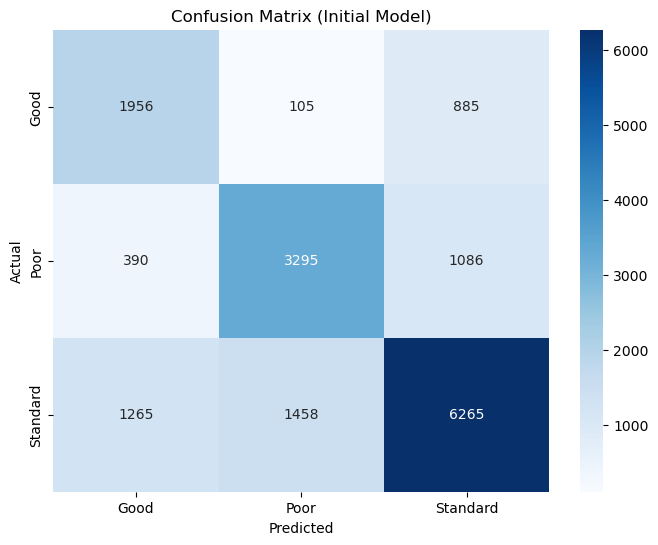

In [35]:
# Initial model
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns

conf_matrix_initial = confusion_matrix(y_test_encoded, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_initial, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Initial Model)')
plt.show()

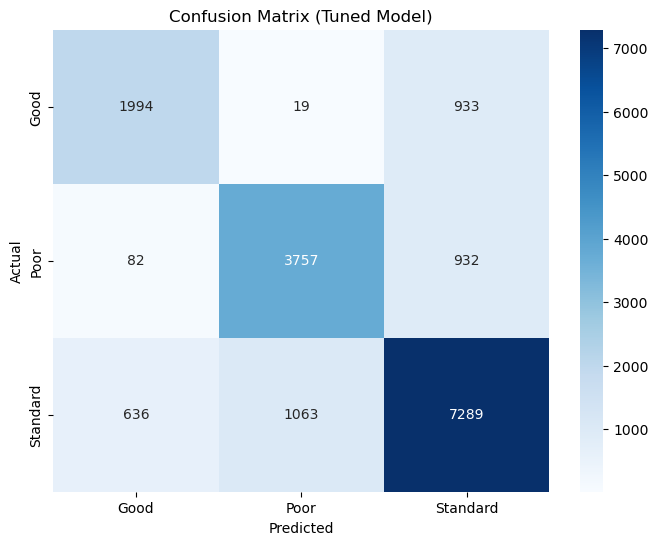

In [37]:
# Optimized model
conf_matrix_tuned = confusion_matrix(y_test_encoded, y_pred_best)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_tuned, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (Tuned Model)')
plt.show()

In [39]:
df['credit_score'].value_counts(dropna=False, normalize=True)

credit_score
Standard    0.5323260380249988
Poor       0.29009625975767445
Good       0.17757770221732674
Name: proportion, dtype: float64

In [140]:
xgb_model = xgb.XGBClassifier(alpha=0.1, colsample_bytree=0.8, learning_rate=0.1, max_depth=10, 
                                n_estimators=500, subsample=0.8, random_state=42)

xgb_model.fit(X_train_processed, y_train_encoded)

cv_results = cross_val_score(xgb_model, X_test_processed, y_test_encoded, cv=5, scoring='f1_weighted')
results.append(cv_results)

## End of XGBoost

# Predictive Model: Random Forest Algorithm

### Pseudocode of Random Forest:
```
Precondition: A training set S := (x1, y1), . . . ,(xn, yn), features F, and number of trees in forest B.

function RandomForest(S,F)
    H ← ∅
    for i ∈ 1, . . . , B do
        S(i) ← A bootstrap sample from S
        hi ← RandomizedTreeLearn(S(i), F)
        H ← H ∪ {hi}
    end for
    return H
end function

function RandomizedTreeLearn(S , F)
    At each node:
        f ← very small subset of F
        Split on best feature in f
    return The learned tree
end function
```

In [164]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder

# Same Train split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=108)

# Replace NaN values in loan_types columns with "Missing"
for col in ['loan_types', 'loan_types_2', 'loan_types_3', 'loan_types_4', 
            'loan_types_5', 'loan_types_6', 'loan_types_7', 
            'loan_types_8', 'loan_types_9']:
    X_train[col] = X_train[col].fillna('Missing')
    X_test[col] = X_test[col].fillna('Missing')

# Identify categorical columns
categorical_cols = ['loan_types', 'loan_types_2', 'loan_types_3', 'loan_types_4', 
                    'loan_types_5', 'loan_types_6', 'loan_types_7', 
                    'loan_types_8', 'loan_types_9', 
                    'customer_occupation', 'credit_mix', 
                    'min_amount_payment', 'payment_behavior']

# Initialize a LabelEncoder
label_encoders = {}

# Apply Label Encoding to categorical columns
for col in categorical_cols:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col])
    X_test[col] = le.transform(X_test[col])
    label_encoders[col] = le

# Use RandomForest with class_weight='balanced' to handle imbalanced data
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')

# Train the model by stratified training
rf_model.fit(X_train, y_train)

RandomForestClassifier(class_weight='balanced', random_state=42)

Accuracy: 0.7950
Classification Report:
              precision    recall  f1-score   support

        Good       0.76      0.69      0.73      2966
        Poor       0.80      0.79      0.80      4846
    Standard       0.80      0.83      0.82      8893

    accuracy                           0.80     16705
   macro avg       0.79      0.77      0.78     16705
weighted avg       0.79      0.80      0.79     16705

Confusion Matrix:
[[2059   19  888]
 [  80 3844  922]
 [ 574  941 7378]]


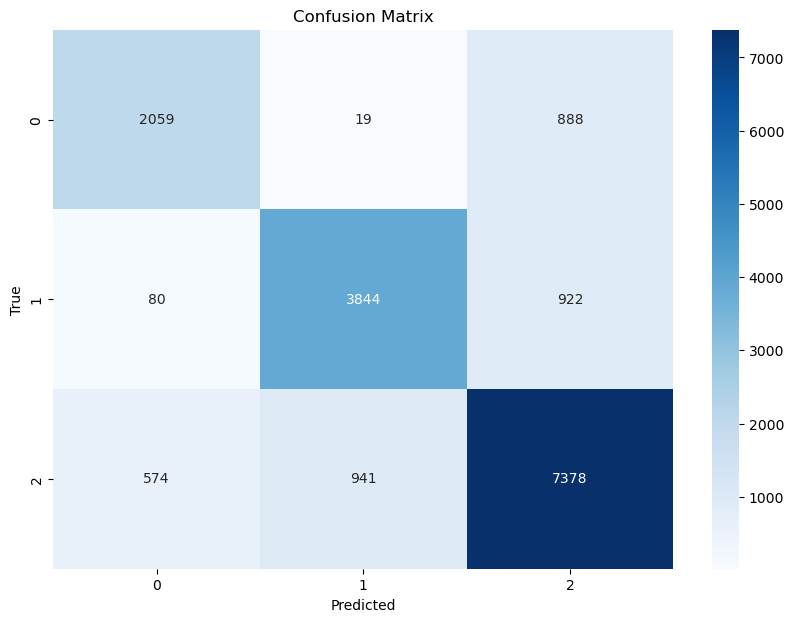

Feature ranking:
1. outstanding_debt (0.1060)
2. interest_rate (0.0842)
3. payment_delay_days (0.0645)
4. credit_history_age_months (0.0501)
5. credit_limit_changes (0.0479)
6. credit_inquiries (0.0466)
7. credit_mix (0.0458)
8. bank_accounts (0.0393)
9. delayed_payments (0.0360)
10. annual_income (0.0358)
11. credit_cards (0.0356)
12. monthly_balance (0.0355)
13. monthly_emi (0.0349)
14. min_amount_payment (0.0344)
15. credit_utilization (0.0329)
16. monthly_investment (0.0322)
17. monthly_salary (0.0310)
18. customer_age (0.0306)
19. record_month (0.0306)
20. customer_occupation (0.0240)
21. loans (0.0205)
22. loan_types (0.0191)
23. loan_types_2 (0.0169)
24. payment_behavior (0.0159)
25. loan_types_3 (0.0148)
26. loan_types_4 (0.0121)
27. loan_types_5 (0.0089)
28. loan_types_6 (0.0062)
29. loan_types_7 (0.0039)
30. loan_types_8 (0.0022)
31. loan_types_9 (0.0016)


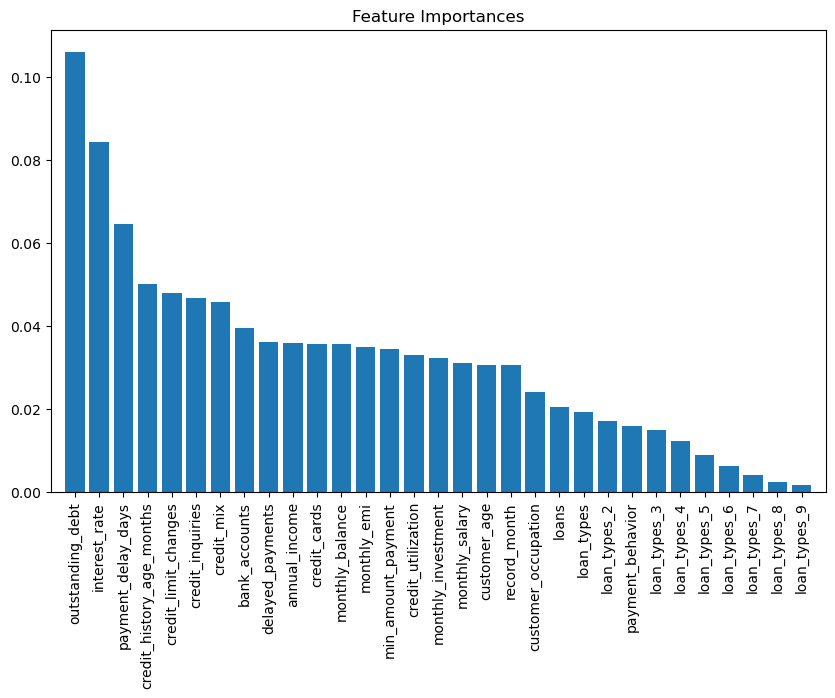

In [165]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns
# Prediction
y_pred = rf_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
print("Confusion Matrix:")
conf_matrix = confusion_matrix(y_test, y_pred)
print(conf_matrix)

plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Feature importances
importances = rf_model.feature_importances_
feature_names = X_train.columns
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(X_train.shape[1]):
    print(f"{f + 1}. {feature_names[indices[f]]} ({importances[indices[f]]:.4f})")

plt.figure(figsize=(10, 6))
plt.title("Feature Importances")
plt.bar(range(X_train.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train.shape[1]), feature_names[indices], rotation=90)
plt.xlim([-1, X_train.shape[1]])
plt.show()

In [143]:
# Predictions with rf_model.predict(X_test)
y_pred = rf_model.predict(X_test)

# Weighted F1 score
f1 = f1_score(y_test, y_pred, average='weighted')

# Cohen's Kappa
kappa = cohen_kappa_score(y_test, y_pred)

print(f'Weighted F1 Score: {f1:.4f}')
print(f"Cohen's Kappa: {kappa:.4f}")

Weighted F1 Score: 0.7895
Cohen's Kappa: 0.6462


In [54]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

# Define the parameter grid
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2'],
    'class_weight': ['balanced', None]
}

# RandomForestClassifier
rf = RandomForestClassifier(random_state=42)

# GridSearchCV by hyperparameter tuning
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid,
                           scoring='f1_weighted', cv=5, verbose=2, n_jobs=-1)

# Hyperparameter tuning
grid_search.fit(X_train_encoded, y_train)

# Best parameters
print("Best parameters:", grid_search.best_params_)

Fitting 5 folds for each of 432 candidates, totalling 2160 fits
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=  12.0s
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=300; total time=  36.3s


[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=200; total time=  24.4s
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=300; total time=  35.4s
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=  12.1s
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=  11.5s
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=100; total time=  12.0s
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=5, n_estimators=300; total time=  35.2s
[CV] END class_weight=balanced, max_depth=None, max_features=sqrt, min_samples_leaf=1, min_samples_split=2, n_estimators=100; tota

In [168]:
# Random Forest with best parameters
rf_model = RandomForestClassifier(
    n_estimators=300, 
    random_state=42, 
    class_weight=None,
    max_depth=None,
    min_samples_split=2, 
    min_samples_leaf=1, 
    max_features='sqrt'
)

# Train the model by stratified training
rf_model.fit(X_train, y_train)

RandomForestClassifier(n_estimators=300, random_state=42)

Accuracy: 0.7978
Classification Report:
              precision    recall  f1-score   support

        Good       0.74      0.72      0.73      2966
        Poor       0.80      0.81      0.80      4846
    Standard       0.82      0.82      0.82      8893

    accuracy                           0.80     16705
   macro avg       0.78      0.78      0.78     16705
weighted avg       0.80      0.80      0.80     16705

Confusion Matrix:
[[2145   17  804]
 [ 110 3910  826]
 [ 657  963 7273]]


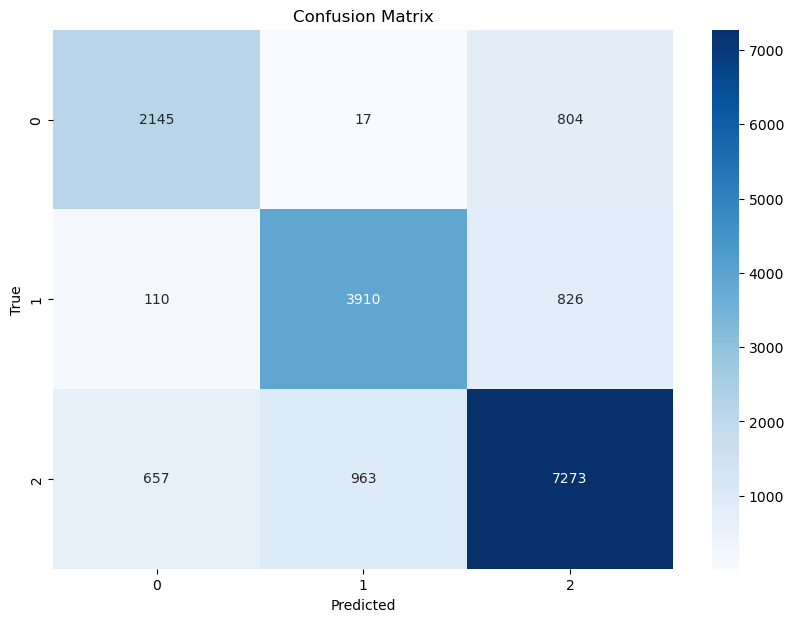

Feature ranking:
1. outstanding_debt (0.0996)
2. interest_rate (0.0741)
3. payment_delay_days (0.0563)
4. credit_limit_changes (0.0521)
5. credit_mix (0.0497)
6. credit_history_age_months (0.0478)
7. credit_inquiries (0.0431)
8. credit_cards (0.0408)
9. monthly_balance (0.0398)
10. credit_utilization (0.0381)
11. delayed_payments (0.0378)
12. annual_income (0.0377)
13. monthly_investment (0.0366)
14. monthly_emi (0.0361)
15. monthly_salary (0.0342)
16. bank_accounts (0.0342)
17. customer_age (0.0329)
18. record_month (0.0302)
19. customer_occupation (0.0256)
20. loans (0.0220)
21. loan_types (0.0206)
22. min_amount_payment (0.0196)
23. loan_types_2 (0.0189)
24. payment_behavior (0.0177)
25. loan_types_3 (0.0163)
26. loan_types_4 (0.0132)
27. loan_types_5 (0.0082)
28. loan_types_6 (0.0071)
29. loan_types_7 (0.0051)
30. loan_types_8 (0.0029)
31. loan_types_9 (0.0019)


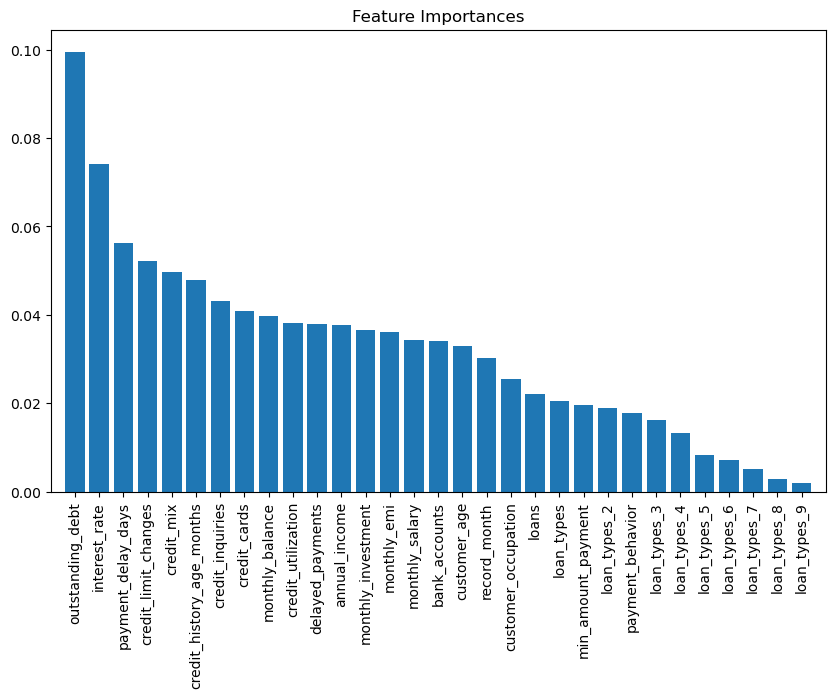

In [169]:
# Prediction
y_pred = rf_model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")

# Classification Report
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
print("Confusion Matrix:")
conf_matrix = confusion_matrix(y_test, y_pred)
print(conf_matrix)

plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Feature importances
importances = rf_model.feature_importances_
feature_names = X_train.columns
indices = np.argsort(importances)[::-1]

print("Feature ranking:")
for f in range(X_train.shape[1]):
    print(f"{f + 1}. {feature_names[indices[f]]} ({importances[indices[f]]:.4f})")

plt.figure(figsize=(10, 6))
plt.title("Feature Importances")
plt.bar(range(X_train.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train.shape[1]), feature_names[indices], rotation=90)
plt.xlim([-1, X_train.shape[1]])
plt.show()

In [170]:
# Predictions with rf_model.predict(X_test)
y_pred = rf_model.predict(X_test)

# Weighted F1 score
f1 = f1_score(y_test, y_pred, average='weighted')

# Cohen's Kappa
kappa = cohen_kappa_score(y_test, y_pred)

print(f'Weighted F1 Score: {f1:.4f}')
print(f"Cohen's Kappa: {kappa:.4f}")

Weighted F1 Score: 0.7977
Cohen's Kappa: 0.6633


In [159]:
cv_results = cross_val_score(rf_model, X_test, y_test, cv=5, scoring='f1_weighted')
results.append(cv_results)

# Group Component 2

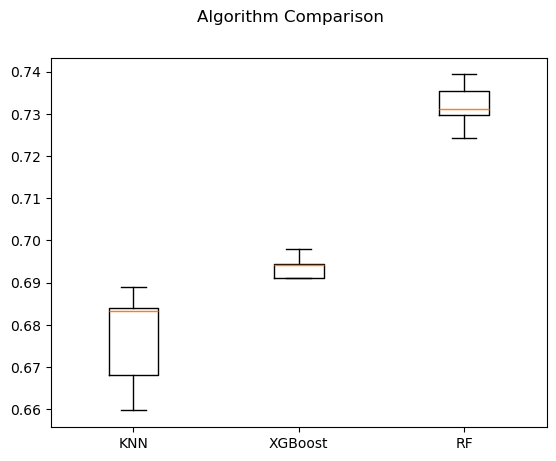

In [160]:
names = ['KNN', 'XGBoost', 'RF']
fig = plt.figure()
fig.suptitle('Algorithm Comparison')
ax = fig.add_subplot(111)
plt.boxplot(results)
ax.set_xticklabels(names)
plt.show()

## End of Group Component 2